In [ ]:
#Cell 1
!pip install -q pillow-heif

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 102.3 MB/s eta 0:00:00


In [ ]:
# Cell 2: Nhập các thư viện cần thiết (Import Libraries)
import os             # Thư viện để quản lý hệ thống file và thư mục
import shutil         # Thư viện để sao chép, di chuyển hoặc xóa thư mục/file
import random         # Thư viện tạo số ngẫu nhiên (dùng để xáo trộn ảnh)
from pathlib import Path # Thư viện quản lý đường dẫn file một cách chuyên nghiệp

import numpy as np    # Thư viện tính toán với mảng (matrix) cực nhanh
import pandas as pd   # Thư viện để xử lý dữ liệu dạng bảng
import matplotlib.pyplot as plt # Thư viện để vẽ biểu đồ và hiển thị ảnh

from PIL import Image # Thư viện xử lý hình ảnh cơ bản
import pillow_heif    # Thư viện hỗ trợ mở ảnh định dạng .heic (từ iPhone)

import tensorflow as tf # Thư viện chính để xây dựng và huấn luyện AI
from tensorflow.keras import layers # Các lớp (layer) để xây dựng mô hình
from tensorflow.keras.models import Model # Công cụ để tạo cấu trúc mô hình
from tensorflow.keras.applications import MobileNetV2 # Kiến trúc AI "nổi tiếng" đã được train sẵn
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input # Hàm tiền xử lý ảnh cho MobileNetV2

# Công cụ để đánh giá độ thông minh của AI sau khi train
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Đăng ký để Python có thể mở được ảnh định dạng HEIC (thường thấy trên điện thoại Apple)
pillow_heif.register_heif_opener()

print("TensorFlow version:", tf.__version__) # Kiểm tra phiên bản TensorFlow
print("Notebook đã sẵn sàng.")

TensorFlow version: 2.20.0
Notebook đã sẵn sàng.


In [ ]:
#Cell 3
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#Cell 4
RAW_DIR = Path("/content/drive/MyDrive/[AIC]")

print("RAW_DIR:", RAW_DIR)
print("Folder tồn tại:", RAW_DIR.exists())

if RAW_DIR.exists():
    print("\nCác thư mục bên trong:")
    for p in RAW_DIR.iterdir():
        print("-", p.name)
else:
    print("\nKhông tìm thấy folder.")
    print("Bạn cần upload folder vào Drive của tôi trước.")

RAW_DIR: /content/drive/MyDrive/[AIC]
Folder tồn tại: True

Các thư mục bên trong:
- Model_Output
- LOW FLOODED
- NO FLOODED
- HEAVY FLOODED


In [ ]:
# Cell 5: Chuẩn hóa toàn bộ ảnh về định dạng .jpg để dataset đồng nhất
OUT_DIR = Path("/content/NO_LOW_HEAVY_jpg")  # Đổi tên thư mục đích cho bao quát 4 lớp

# Định nghĩa các lớp (classes) muốn phân loại và tên thư mục tương ứng
CLASS_MAP = {
    "NO FLOODED": "NO FLOODED",
    "LOW FLOODED": "LOW FLOODED",
    "HEAVY FLOODED": "HEAVY FLOODED",
}
# Các định dạng file ảnh được phép xử lý
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".heic", ".heif"}

# Xóa thư mục cũ (nếu tồn tại) để tránh nhầm lẫn dữ liệu, sau đó tạo lại thư mục trống
if OUT_DIR.exists():
    shutil.rmtree(OUT_DIR)
OUT_DIR.mkdir(parents=True, exist_ok=True)

total_saved = 0 # Biến đếm tổng số ảnh đã lưu thành công

# Lặp qua từng lớp (class) trong danh sách CLASS_MAP
for source_folder, class_name in CLASS_MAP.items():
    src_dir = RAW_DIR / source_folder  # Đường dẫn thư mục ảnh thô ban đầu
    dst_dir = OUT_DIR / class_name    # Đường dẫn thư mục đích
    dst_dir.mkdir(parents=True, exist_ok=True) # Tạo thư mục đích nếu chưa có

    # Kiểm tra xem thư mục nguồn có tồn tại không
    if not src_dir.exists():
        print(f"Không tìm thấy folder class: {src_dir}")
        continue

    # Lọc lấy danh sách các file ảnh hợp lệ trong thư mục nguồn
    files = [
        p for p in src_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMG_EXTS
    ]

    print(f"\nClass {class_name}: {len(files)} ảnh gốc")

    saved_count = 0
    # Xử lý từng ảnh một
    for i, src in enumerate(files):
        try:
            # Mở ảnh và chuyển sang hệ màu RGB (để loại bỏ kênh alpha của file PNG nếu có)
            img = Image.open(src).convert("RGB")
            # Đặt tên mới cho ảnh theo định dạng: Class_SốThứTự.jpg
            dst = dst_dir / f"{class_name}_{i:04d}.jpg"
            # Lưu ảnh thành định dạng JPEG với chất lượng cao (quality=95)
            img.save(dst, "JPEG", quality=95)
            saved_count += 1
        except Exception as e:
            print("Lỗi ảnh:", src.name, "|", e) # Thông báo nếu file bị lỗi không mở được

    print(f"Đã lưu {saved_count} ảnh JPG cho class {class_name}")
    total_saved += saved_count

print("\nTổng số ảnh đã xử lý:", total_saved)
print("Dataset JPG nằm tại:", OUT_DIR)


Class NO FLOODED: 405 ảnh gốc
Đã lưu 405 ảnh JPG cho class NO FLOODED

Class LOW FLOODED: 406 ảnh gốc
Đã lưu 406 ảnh JPG cho class LOW FLOODED

Class HEAVY FLOODED: 357 ảnh gốc
Đã lưu 357 ảnh JPG cho class HEAVY FLOODED

Tổng số ảnh đã xử lý: 1168
Dataset JPG nằm tại: /content/NO_LOW_HEAVY_jpg


In [ ]:
#Cell 6 Đếm số lượng ảnh
for class_name in CLASS_MAP.values():
    class_dir = OUT_DIR / class_name
    num_images = len(list(class_dir.glob("*.jpg")))
    print(class_name, ":", num_images, "ảnh")

NO FLOODED : 405 ảnh
LOW FLOODED : 406 ảnh
HEAVY FLOODED : 357 ảnh


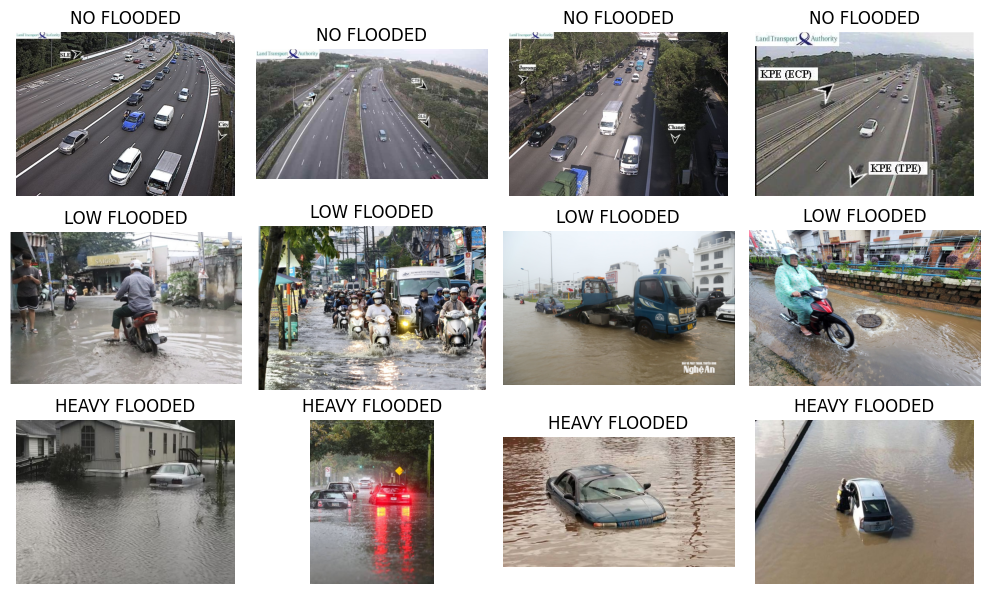

In [ ]:
#Cell 7
plt.figure(figsize=(10, 6))

image_paths = []

for class_name in CLASS_MAP.values():
    class_dir = OUT_DIR / class_name
    image_paths.extend(list(class_dir.glob("*.jpg"))[:4])

for i, img_path in enumerate(image_paths[:12]):
    img = Image.open(img_path)
    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title(img_path.parent.name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Cell 8: Chia dữ liệu thành tập Train (80%) và tập Validation (20%)
SPLIT_DIR = Path("/content/NO_LOW_HEAVY_split") # Thư mục đích chứa dữ liệu sau khi chia

TRAIN_RATIO = 0.8 # Tỷ lệ dành cho tập Train (80%)
SEED = 42 # Đặt hạt giống ngẫu nhiên để kết quả chia luôn giống nhau mỗi lần chạy
random.seed(SEED)

# Xóa thư mục cũ (nếu có) và tạo mới cấu trúc thư mục train/val
if SPLIT_DIR.exists():
    shutil.rmtree(SPLIT_DIR)

for split in ["train", "val"]:
    for class_name in CLASS_MAP.values():
        (SPLIT_DIR / split / class_name).mkdir(parents=True, exist_ok=True)

# Bắt đầu quá trình chia dữ liệu cho từng loại class (Bottle, Grass)
for class_name in CLASS_MAP.values():
    src_dir = OUT_DIR / class_name
    files = list(src_dir.glob("*.jpg")) # Lấy danh sách tất cả file ảnh của class đó

    random.shuffle(files) # Xáo trộn ngẫu nhiên thứ tự ảnh để đảm bảo tính khách quan

    # Logic chia tỉ lệ Train/Val
    if len(files) <= 1: # Nếu chỉ có 1 hoặc 0 ảnh thì không chia, cho tất cả vào Train
        train_files = files
        val_files = []
    else:
        split_idx = int(len(files) * TRAIN_RATIO) # Tính vị trí cắt dựa trên tỉ lệ 0.8

        # Đảm bảo vẫn còn ảnh cho tập Val nếu dữ liệu quá ít
        if split_idx >= len(files): split_idx = len(files) - 1
        if split_idx <= 0: split_idx = 1

        train_files = files[:split_idx] # Cắt lấy phần Train
        val_files = files[split_idx:]   # Cắt lấy phần còn lại cho Val

    print(f"\nClass: {class_name}")
    print("Total:", len(files), "| Train:", len(train_files), "| Val:", len(val_files))

    # Sao chép file ảnh từ thư mục gốc vào thư mục train hoặc val tương ứng
    for src in train_files:
        dst = SPLIT_DIR / "train" / class_name / src.name
        shutil.copy(src, dst)

    for src in val_files:
        dst = SPLIT_DIR / "val" / class_name / src.name
        shutil.copy(src, dst)

print("\nĐã chia dataset tại:", SPLIT_DIR)


Class: NO FLOODED
Total: 405 | Train: 324 | Val: 81

Class: LOW FLOODED
Total: 406 | Train: 324 | Val: 82

Class: HEAVY FLOODED
Total: 357 | Train: 285 | Val: 72

Đã chia dataset tại: /content/NO_LOW_HEAVY_split


In [ ]:
#Cell 9
for split in ["train", "val"]:
    print(f"\n{split.upper()}")
    for class_name in CLASS_MAP.values():
        folder = SPLIT_DIR / split / class_name
        count = len(list(folder.glob("*.jpg")))
        print(class_name, ":", count)


TRAIN
NO FLOODED : 324
LOW FLOODED : 324
HEAVY FLOODED : 285

VAL
NO FLOODED : 81
LOW FLOODED : 82
HEAVY FLOODED : 72


In [ ]:
# Cell 10: Nạp dữ liệu vào mô hình (Data Loading)
IMG_SIZE = (224, 224) # Kích thước chuẩn cho ảnh đầu vào (chiều rộng, chiều cao)
BATCH_SIZE = 16       # Số lượng ảnh mô hình sẽ học trong mỗi lần cập nhật (1 batch = 16 ảnh)

# Trỏ đường dẫn đến thư mục chứa ảnh train và val đã chia ở Cell 8
TRAIN_DIR = SPLIT_DIR / "train"
VAL_DIR = SPLIT_DIR / "val"

# Tạo bộ dữ liệu Train từ thư mục
# shuffle=True: Xáo trộn ngẫu nhiên ảnh trong mỗi epoch để mô hình không học vẹt thứ tự
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

# Tạo bộ dữ liệu Validation (để đánh giá)
# shuffle=False: Không cần xáo trộn khi đánh giá để kết quả kiểm tra nhất quán
val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Tự động lấy danh sách tên lớp (classes) từ tên thư mục (vd: Bottle, Grass)
class_names = train_ds.class_names
num_classes = len(class_names) # Đếm xem có bao nhiêu loại đối tượng cần phân loại

print("Class names:", class_names)
print("Number of classes:", num_classes)

Found 933 files belonging to 3 classes.
Found 235 files belonging to 3 classes.
Class names: ['HEAVY FLOODED', 'LOW FLOODED', 'NO FLOODED']
Number of classes: 3


In [ ]:
# Cell 11: Tối ưu hóa tốc độ nạp dữ liệu bằng kỹ thuật Prefetch
# AUTOTUNE giúp TensorFlow tự động tính toán số lượng batch cần chuẩn bị sẵn dựa trên tài nguyên máy
AUTOTUNE = tf.data.AUTOTUNE

# .prefetch(buffer_size=AUTOTUNE) có tác dụng:
# Trong lúc mô hình đang "học" (training) trên batch hiện tại,
# dữ liệu của batch tiếp theo sẽ được chuẩn bị sẵn ở background.
# Việc này giúp loại bỏ thời gian chờ đợi (bottleneck) giữa việc nạp và xử lý dữ liệu.

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

print("Dataset đã được tối ưu bằng prefetch.")

Dataset đã được tối ưu bằng prefetch.


In [ ]:
# Cell 12: Xây dựng kiến trúc mô hình AI sử dụng Transfer Learning
# Sử dụng MobileNetV2 - một mô hình cực nhẹ và nhanh, rất phù hợp cho thiết bị di động
base_model = MobileNetV2(
    weights="imagenet",   # Lấy kiến thức đã học từ tập dữ liệu khổng lồ ImageNet
    include_top=False,    # Bỏ qua lớp phân loại cũ, chỉ lấy "phần thân" (để nhận diện đặc trưng)
    input_shape=(224, 224, 3) # Định nghĩa kích thước ảnh đầu vào (dài, rộng, 3 kênh màu RGB)
)

# Đóng băng các lớp của base_model để không làm hỏng kiến thức đã học trước đó trong quá trình train
base_model.trainable = False

# Xây dựng các lớp mới phía trên dựa trên đặc trưng của base_model
inputs = tf.keras.Input(shape=(224, 224, 3)) # Lớp đầu vào của mô hình

x = preprocess_input(inputs)       # Tiền xử lý ảnh theo yêu cầu của MobileNetV2
x = base_model(x, training=False)  # Đưa ảnh qua phần thân của MobileNetV2
x = layers.GlobalAveragePooling2D()(x) # Nén các đặc trưng về dạng vector đơn giản
x = layers.Dropout(0.3)(x)         # Ngắt ngẫu nhiên 30% kết nối để tránh học vẹt (Overfitting)

# Lớp cuối cùng: Phân loại rác (số lượng lớp = num_classes)
# Dùng "softmax" để đưa ra xác suất dự đoán cho từng loại
outputs = layers.Dense(num_classes, activation="softmax")(x)

# Kết nối mọi thứ thành một mô hình hoàn chỉnh
model = Model(inputs, outputs)

# Cấu hình cách mô hình học tập
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4), # Thuật toán tối ưu hóa (giúp giảm lỗi)
    loss="sparse_categorical_crossentropy",                # Hàm đo độ sai lệch
    metrics=["accuracy"]                                    # Chỉ số theo dõi: độ chính xác
)

# Hiển thị cấu trúc mô hình để học sinh xem các lớp bên trong
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
# Cell 13: Bắt đầu quá trình huấn luyện mô hình (Training)
EPOCHS = 80  # Số vòng lặp: toàn bộ tập dữ liệu train sẽ được mô hình "học đi học lại" 10 lần

# model.fit: Lệnh kích hoạt quá trình học
history = model.fit(
    train_ds,            # Dữ liệu dùng để học (80% dataset)
    validation_data=val_ds, # Dữ liệu dùng để "thi thử" sau mỗi vòng lặp (20% dataset)
    epochs=EPOCHS        # Số lần lặp lại toàn bộ quá trình học
)

Epoch 1/80
59/59 ━━━━━━━━━━━━━━━━━━━━ 59s 883ms/step - accuracy: 0.4834 - loss: 1.1353 - val_accuracy: 0.6170 - val_loss: 0.8504
Epoch 2/80
59/59 ━━━━━━━━━━━━━━━━━━━━ 51s 857ms/step - accuracy: 0.6056 - loss: 0.8771 - val_accuracy: 0.6936 - val_loss: 0.6823
Epoch 3/80
59/59 ━━━━━━━━━━━━━━━━━━━━ 91s 1s/step - accuracy: 0.6817 - loss: 0.6847 - val_accuracy: 0.7106 - val_loss: 0.5970
Epoch 4/80
59/59 ━━━━━━━━━━━━━━━━━━━━ 60s 1s/step - accuracy: 0.7074 - loss: 0.6260 - val_accuracy: 0.7319 - val_loss: 0.5393
Epoch 5/80
59/59 ━━━━━━━━━━━━━━━━━━━━ 52s 884ms/step - accuracy: 0.7535 - loss: 0.5473 - val_accuracy: 0.7404 - val_loss: 0.5003
Epoch 6/80
59/59 ━━━━━━━━━━━━━━━━━━━━ 81s 862ms/step - accuracy: 0.7481 - loss: 0.5387 - val_accuracy: 0.7574 - val_loss: 0.4716
Epoch 7/80
59/59 ━━━━━━━━━━━━━━━━━━━━ 52s 876ms/step - accuracy: 0.7953 - loss: 0.4822 - val_accuracy: 0.7660 - val_loss: 0.4474
Epoch 8/80
59/59 ━━━━━━━━━━━━━━━━━━━━ 60s 1s/step - accuracy: 0.7931 - loss: 0.4432 - val_accuracy: 0.7

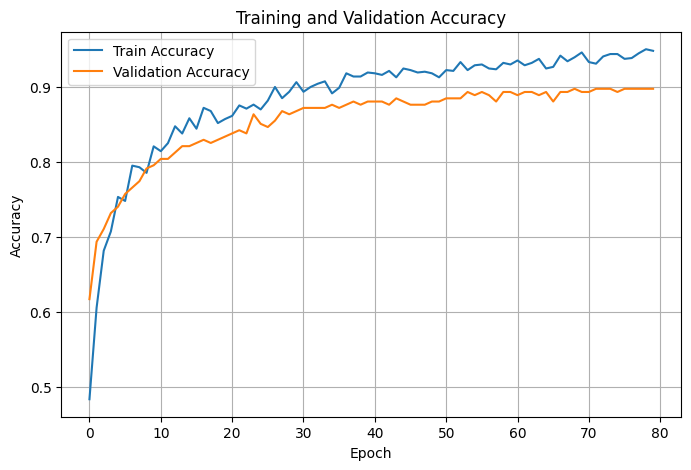

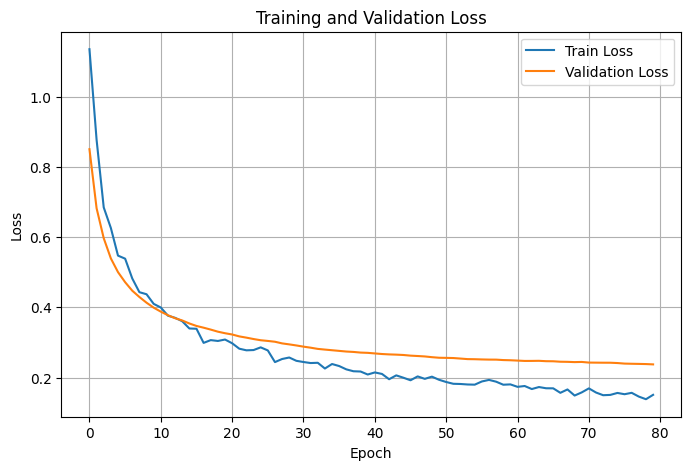

In [ ]:
#Cell 14
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]

loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs_range = range(len(acc))

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, acc, label="Train Accuracy")
plt.plot(epochs_range, val_acc, label="Validation Accuracy")
plt.legend()
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, loss, label="Train Loss")
plt.plot(epochs_range, val_loss, label="Validation Loss")
plt.legend()
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

In [ ]:
#Cell 15
val_loss, val_acc = model.evaluate(val_ds)

print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_acc)
print("Validation Accuracy (%):", round(val_acc * 100, 2))

15/15 ━━━━━━━━━━━━━━━━━━━━ 15s 931ms/step - accuracy: 0.8979 - loss: 0.2375
Validation Loss: 0.23749172687530518
Validation Accuracy: 0.8978723287582397
Validation Accuracy (%): 89.79


<Figure size 600x600 with 0 Axes>

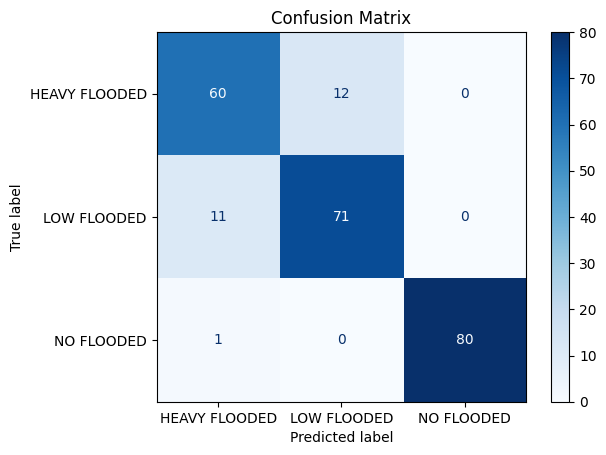

               precision    recall  f1-score   support

HEAVY FLOODED       0.83      0.83      0.83        72
  LOW FLOODED       0.86      0.87      0.86        82
   NO FLOODED       1.00      0.99      0.99        81

     accuracy                           0.90       235
    macro avg       0.90      0.90      0.90       235
 weighted avg       0.90      0.90      0.90       235



In [ ]:
# Cell 16: Đánh giá mô hình bằng Confusion Matrix và Báo cáo chi tiết
y_true = [] # Danh sách chứa nhãn thật (đáp án đúng)
y_pred = [] # Danh sách chứa nhãn dự đoán (kết quả của AI)

# Lặp qua tập dữ liệu kiểm thử (val_ds) để so sánh kết quả
for images, labels in val_ds:
    preds = model.predict(images, verbose=0)     # AI dự đoán xác suất cho từng loại rác
    pred_labels = np.argmax(preds, axis=1)        # Lấy nhãn có xác suất cao nhất

    y_true.extend(labels.numpy())                 # Thêm đáp án thật vào danh sách
    y_pred.extend(pred_labels)                    # Thêm dự đoán của AI vào danh sách

# Tạo ma trận nhầm lẫn: Bảng so sánh giữa dự đoán và thực tế
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(num_classes))
)

# Hiển thị ma trận dưới dạng hình ảnh
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

plt.figure(figsize=(6, 6))
disp.plot(cmap="Blues", values_format="d") # Sử dụng tone màu xanh để dễ nhìn
plt.title("Confusion Matrix")
plt.show()

# Xuất báo cáo chi tiết: Precision, Recall và F1-Score cho từng loại rác
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    labels=list(range(num_classes)),
    zero_division=0 # Tránh lỗi chia cho 0 nếu AI không dự đoán đúng lớp nào
))

In [ ]:
# Cell 17: Lưu model vào folder Bottle and Grass trên Google Drive

from pathlib import Path
import json

# Folder gốc của bạn trên Drive
RAW_DIR = Path("/content/drive/MyDrive/[AIC]")

# Folder để lưu model
SAVE_DIR = RAW_DIR / "Model_Output"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# Đường dẫn lưu model
MODEL_PATH = SAVE_DIR / "NO_LOW_HEAVY.keras"

# Lưu model
model.save(MODEL_PATH)

# Lưu tên class để sau này load model còn biết 0 là Bottle, 1 là Grass
CLASS_NAMES_PATH = SAVE_DIR / "class_names.json"

with open(CLASS_NAMES_PATH, "w", encoding="utf-8") as f:
    json.dump(class_names, f, ensure_ascii=False, indent=4)

print("Đã lưu model tại:")
print(MODEL_PATH)

print("\nĐã lưu class names tại:")
print(CLASS_NAMES_PATH)

print("\nClass names:", class_names)

Đã lưu model tại:
/content/drive/MyDrive/[AIC]/Model_Output/NO_LOW_HEAVY.keras

Đã lưu class names tại:
/content/drive/MyDrive/[AIC]/Model_Output/class_names.json

Class names: ['HEAVY FLOODED', 'LOW FLOODED', 'NO FLOODED']


In [ ]:
# Cell 18: Load lại model từ folder Bottle and Grass / Model_Output

import tensorflow as tf
import json
from pathlib import Path

RAW_DIR = Path("/content/drive/MyDrive/[AIC]")
SAVE_DIR = RAW_DIR / "Model_Output"

MODEL_PATH = SAVE_DIR / "NO_LOW_HEAVY.keras"
CLASS_NAMES_PATH = SAVE_DIR / "class_names.json"

loaded_model = tf.keras.models.load_model(MODEL_PATH)

with open(CLASS_NAMES_PATH, "r", encoding="utf-8") as f:
    class_names = json.load(f)

val_loss, val_acc = loaded_model.evaluate(val_ds)

print("Loaded model validation accuracy:", round(val_acc * 100, 2), "%")
print("Class names:", class_names)

15/15 ━━━━━━━━━━━━━━━━━━━━ 17s 715ms/step - accuracy: 0.8979 - loss: 0.2375
Loaded model validation accuracy: 89.79 %
Class names: ['HEAVY FLOODED', 'LOW FLOODED', 'NO FLOODED']


Saving images (2).jpeg to images (2) (1).jpeg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step


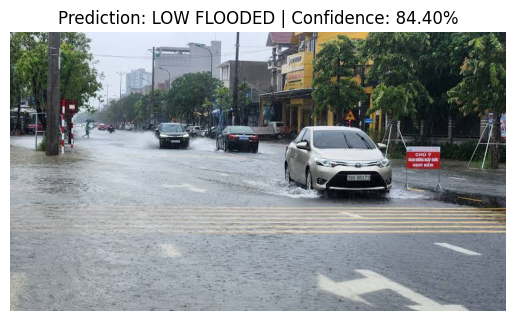

Ảnh: images (2) (1).jpeg
Dự đoán: LOW FLOODED
Độ tin cậy: 84.4 %


In [ ]:
# Cell 19: Tải ảnh mới lên và nhờ AI dự đoán
from google.colab import files

# Mở cửa sổ cho phép học sinh tải ảnh từ máy tính cá nhân lên Colab
uploaded = files.upload()

for filename in uploaded.keys():
    img_path = filename

    # 1. Tiền xử lý ảnh: Mở ảnh và đưa về chuẩn RGB (3 kênh màu)
    img = Image.open(img_path).convert("RGB")
    # Thay đổi kích thước ảnh đúng với kích thước mô hình đã học (IMG_SIZE)
    IMG_SIZE = (224, 224)
    img_resized = img.resize(IMG_SIZE)

    # 2. Chuyển ảnh thành dạng mảng số (array) để AI có thể "đọc" được
    img_array = np.array(img_resized)
    # Thêm một chiều dữ liệu (batch dimension) vì mô hình luôn đợi nhận vào 1 lô ảnh
    img_batch = np.expand_dims(img_array, axis=0)

    # 3. Kích hoạt mô hình dự đoán (Prediction)
    preds = loaded_model.predict(img_batch)

    # 4. Giải mã kết quả: Tìm lớp (class) có xác suất cao nhất
    pred_id = np.argmax(preds[0])         # Tìm vị trí (chỉ số) của lớp có % cao nhất
    pred_class = class_names[pred_id]     # Lấy tên lớp dựa trên chỉ số vừa tìm được
    confidence = preds[0][pred_id]        # Lấy con số % tin cậy của dự đoán đó

    # 5. Hiển thị kết quả trực quan
    plt.imshow(img)
    plt.axis("off") # Tắt hiển thị trục tọa độ
    plt.title(f"Prediction: {pred_class} | Confidence: {confidence*100:.2f}%")
    plt.show()

    # In thông tin chi tiết ra màn hình
    print("Ảnh:", filename)
    print("Dự đoán:", pred_class)
    print("Độ tin cậy:", round(confidence * 100, 2), "%")